# d = 3 cultivation: the double-check on its own, after `reduce_gpf`

> **In short.**
> * **The setting.** *Magic-state cultivation* prepares a special (magic) state, protected by a code, and keeps checking it so that a bad state is thrown away. Its last part, the **double-check**, measures whether the state is the right one.
> * **The question.** What does the double-check do, exactly, as a map on the seven code qubits?
> * **The answer.** After `reduce_gpf`, up to a scalar: $Z_6^{c_{24}} \cdot (I + (-1)^{c_{24}} H^{\otimes 7})$ with $H = (X+Y)/\sqrt2$. It measures the operator $H^{\otimes 7}$, with result `c[24]`, and applies $Z$ to qubit 6 when `c[24]` is 1; on the code this is a measurement of the protected qubit in the basis $\{T^\dagger|+\rangle, T^\dagger|-\rangle\}$. The six detectors the tool finds are exactly the last six `DETECTOR` lines of the circuit file. Both are checked by tensor contraction.
> * **How to read the pictures.** Lines are qubits and time runs left to right; green and red dots are Z- and X-spiders; `π/4` on a green dot is a $T$ and `7π/4` a $T^\dagger$; a measurement is a red dot whose phase is its result, `c[...]`.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

This notebook takes only the **double-check** of the d = 3 cultivation circuit, cuts it out of the program's ZX-diagram, and reduces it with `reduce_gpf`. The circuit is the one of `Cultivation.ipynb`: the file `circuits/cultivation/d3_cultivation.stim` of Wan, Zhong and Zapirain (see `circuits/cultivation/README.md`).

The double-check is the last part of the file, stages 3 and 4 of the program:

* the six helper qubits 15, 10, 5, 2, 7, 1 are prepared in |+⟩, and T† is applied to the seven code qubits 0, 3, 6, 8, 9, 11, 14;
* a ladder of CNOTs, then qubit 6 is measured in the X basis (`MX 6`, outcome `c[24]`) and reset (this ends stage 3);
* the ladder in reverse, T on the seven code qubits, and the six helpers are measured in the X basis (outcomes `c[25]` to `c[30]`).

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pyzx as zx
from pyzx.utils import VertexType, EdgeType
from zxqec.qprogram import program_from_stim
from zxqec.gpf import (reduce_gpf, is_leaf, phase_polynomial, boolean_variables, consistent_assignments,
                       equal_for_all_assignments, phases_modulo, reduce_modulo)
from zxqec.spacetime import draw_program
from zxqec.spacetime.subdiagram import get_logical_qubit

text = open('circuits/cultivation/d3_cultivation.stim').read()
p, circ = program_from_stim(text, names=['first checks', 'inject', 'checks again',
                                         'double-check (T-dag, measure)', 'double-check (T, measure)'])
level = p.group_stages([(0, 0, 'first checks', 'state preparation'), (1, 1, 'inject T', 'injection'),
                        (2, 2, 'checks', 'syndrome extraction'), (3, 4, 'double-check', 'cultivation')])
print(p.describe_level(level))
DC = 3                                                   # the double-check block of this level

Level 4 (4 blocks):
  Block 0 'first checks' (state preparation): [first checks]
  Block 1 'inject T' (injection): [inject]
  Block 2 'checks' (syndrome extraction): [checks again]
  Block 3 'double-check' (cultivation): [double-check (T-dag, measure), double-check (T, measure)]


The whole program, one shade per block of this level: the first checks, the injection of the $T$ state, a round of checks, and the double-check, the last shade, which the rest of this notebook takes on its own.

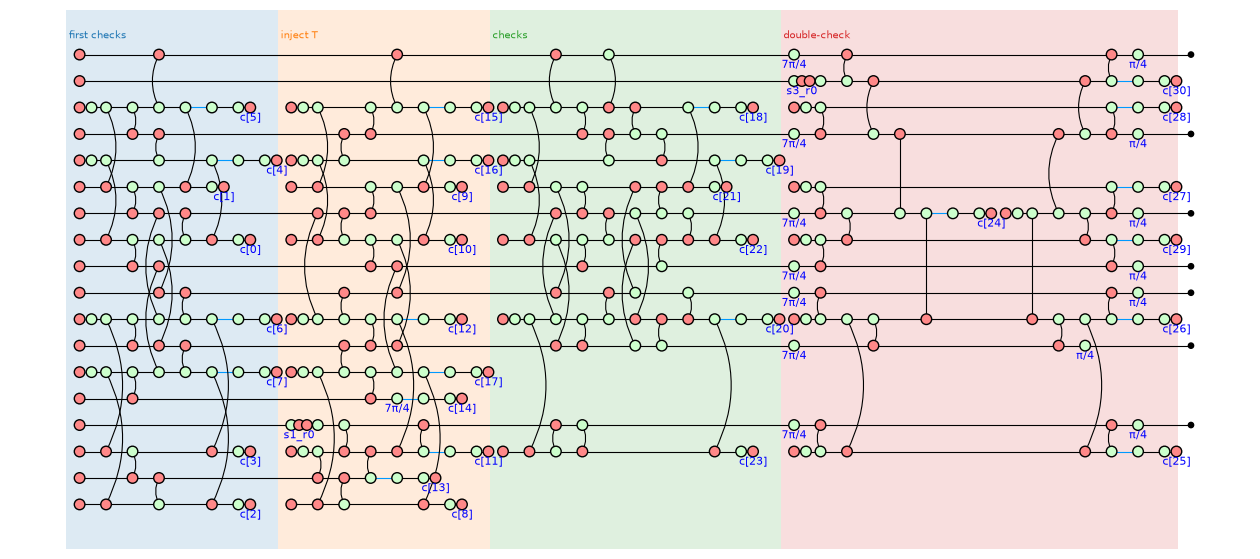

In [2]:
draw_program(p, level=level, show_time=False, labels=False, figsize=(16, 7))

The lines of the file that make up the double-check (`TICK` lines left out). Stage 3 starts where the helpers measured in stage 2 are reset, and stage 4 where qubit 6 is reset after `MX 6`.

In [3]:
start = text.index('RX 15 10 5 2 7 1')
print('\n'.join(line for line in text[start:].splitlines() if line != 'TICK'))

RX 15 10 5 2 7 1
T_DAG 0 3 6 8 9 11 14
CX 1 0 2 3 5 6 7 8 10 9 15 14
CX 3 1 6 7 10 15
CX 6 3 10 11
CX 6 10
MX 6
RX 6
CX 6 10
CX 6 3 10 11
CX 3 1 6 7 10 15
CX 1 0 2 3 5 6 7 8 10 9 15 14
T 0 3 6 8 9 11 14
MX 15 10 5 2 7 1
DETECTOR(1.60714, 0.75, 3, -1, -9) rec[-29] rec[-28] rec[-26] rec[-24] rec[-23] rec[-21] rec[-20] rec[-18] rec[-17] rec[-12] rec[-11] rec[-7]
DETECTOR(4, 1, 4) rec[-6]
DETECTOR(3, 1, 4) rec[-5]
DETECTOR(2, 1, 4) rec[-4] rec[-7]
DETECTOR(1, 0, 4) rec[-3]
DETECTOR(2, 2, 4) rec[-2]
DETECTOR(0, 1, 4) rec[-1]


## The block as a ZX-diagram

`block_graph` cuts the block out of the program's diagram. Its inputs are the qubits alive when the block starts and its outputs the qubits alive when it ends; the outcomes are Boolean variables in the phases.

**Qubit 1.** It is prepared at the start of the circuit (`R 1 14`) and not touched until the double-check resets it (`RX ... 1`). The helpers 15, 10, 5, 2, 7 were measured in stage 2, so their wires end there and their reset here is a plain preparation. Qubit 1 was never measured, so its reset is kept as PyZX models a reset: the old state is discarded by a Z measurement whose outcome nobody records (the reset variable `s3_r0`), and a fresh qubit is prepared. That discard reads the state qubit 1 had *before* the double-check; in the whole program it always reads 0, because qubit 1 is still in |0⟩. So it belongs to what comes before the block, not to the double-check.

In the block's diagram the discard is a separate piece, not connected to anything else. The next cell lists the pieces and leaves that one out, so from here on the double-check is a map from the seven code qubits to themselves. (The tool itself is unchanged: it puts such a discard at the start of the stage that contains the reset.)

In the picture the input wires, which in the program start at the beginning of the circuit, are moved to just before the block.

a piece of  97 spiders: inputs [0, 3, 6, 8, 9, 11, 14], outputs [0, 3, 6, 8, 9, 11, 14], variables ['c[24]', 'c[25]', 'c[26]', 'c[27]', 'c[28]', 'c[29]', 'c[30]']
a piece of   2 spiders: inputs [1], outputs [], variables ['s3_r0']
in the whole program: ['s3_r0 = 0']

the double-check without it: 97 spiders
inputs: qubits  [0, 3, 6, 8, 9, 11, 14]
outputs: qubits [0, 3, 6, 8, 9, 11, 14]
Boolean variables: ['c[24]', 'c[25]', 'c[26]', 'c[27]', 'c[28]', 'c[29]', 'c[30]']


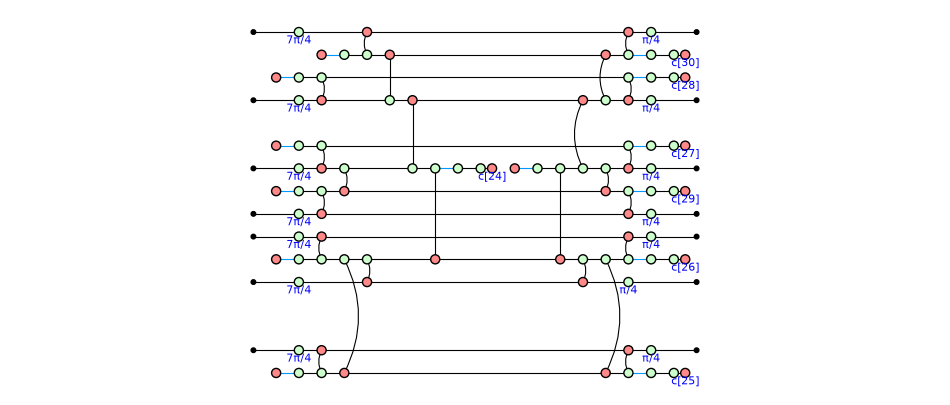

In [4]:
g = p.block_graph(level, DC, classical=False)          # a fresh copy, safe to edit
spiders = lambda h: sum(1 for v in h.vertices() if h.type(v) != VertexType.BOUNDARY)


def pieces(h):
    # the connected pieces of a diagram, as sets of vertices
    left, out = set(h.vertices()), []
    while left:
        stack, piece = [left.pop()], set()
        while stack:
            v = stack.pop()
            if v not in piece:
                piece.add(v)
                stack.extend(h.neighbors(v))
        left -= piece
        out.append(piece)
    return out


for piece in pieces(g):
    print("a piece of {:3d} spiders: inputs {}, outputs {}, variables {}".format(
        sum(1 for v in piece if g.type(v) != VertexType.BOUNDARY),
        [get_logical_qubit(g, b) for b in g.inputs() if b in piece],
        [get_logical_qubit(g, b) for b in g.outputs() if b in piece],
        sorted({str(x) for v in piece if hasattr(g.phase(v), 'free_vars') for x in g.phase(v).free_vars()})))

whole = reduce_gpf(p.quantum_graph())
print("in the whole program:", [str(c) + " = 0" for c in whole.constraints if 's3_r0' in {x.name for x in c.free_vars()}])

(discard,) = [piece for piece in pieces(g) if not any(b in piece for b in g.outputs())]
g.set_inputs(tuple(b for b in g.inputs() if b not in discard))
g.remove_vertices(list(discard))
print()
print("the double-check without it:", spiders(g), "spiders")
print("inputs: qubits ", [get_logical_qubit(g, b) for b in g.inputs()])
print("outputs: qubits", [get_logical_qubit(g, b) for b in g.outputs()])
print("Boolean variables:", sorted(boolean_variables(g)))

shown = g.copy()
first = min(shown.row(v) for v in shown.vertices() if shown.type(v) != VertexType.BOUNDARY)
for b in shown.inputs():
    shown.set_row(b, first - 1)
zx.draw_matplotlib(shown, labels=False, figsize=(12, 5))

## `reduce_gpf`

`reduce_gpf` brings the block into the generalized parity form and reduces it: a layer of Z-spiders (whose bits are summed over), one X-spider per output, and phase gadgets for the T-type phases. It also returns the **detectors of the block**: parities of the block's outcomes that are 0 in every noiseless run of the block, for any input. They are exactly the last six `DETECTOR` lines of the file. The first `DETECTOR` line of this part is not among them: it ties `c[24]` to outcomes from before the block, so it holds only in the whole program.

The last line checks the reduced diagram against the double-check's own diagram (the one above) by tensor contraction, in every assignment of the variables that the detectors allow.

In [5]:
res = reduce_gpf(g)
h = res.graph
leaves = [v for v in h.vertices() if is_leaf(h, v)]
print(spiders(g), "spiders ->", spiders(h), "spiders, of which", len(leaves), "are gadget leaves")
print("detectors of the block (each is 0):", [str(d) for d in res.detectors])
print("the same as the last six DETECTOR lines of the file:",
      {frozenset(d) for d in circ.detectors[-6:]} == {frozenset(v.name for v in d.free_vars()) for d in res.detectors})

names = sorted(set(boolean_variables(g)) | {str(v) for c in res.constraints for v in c.free_vars()})
runs = consistent_assignments(res.constraints, names)
print("equal to the double-check, up to a scalar, in all", len(runs), "allowed runs:",
      equal_for_all_assignments(g, res.to_graph(), names, res.constraints))

97 spiders -> 43 spiders, of which 14 are gadget leaves
detectors of the block (each is 0): ['c[30]', 'c[29]', 'c[26]', 'c[25]', 'c[28]', 'c[24] + c[27]']
the same as the last six DETECTOR lines of the file: True
equal to the double-check, up to a scalar, in all 2 allowed runs: True


## The reduced diagram

Names used below: `in q` is the Z-spider on input `q`, `out q` the X-spider on output `q`, `z1, z2, ...` the other Z-spiders. A gadget is an X-spider (the hub) with a one-legged Z-spider (the leaf) carrying the angle; it adds that angle times the parity of the Z-spiders the hub is joined to. Phases are in units of π. The picture is PyZX's drawing (`zx.draw_matplotlib`) of the library's layout (`layout_gpf`), with the vertex numbers shown and the outcome phases written modulo the block's detectors (`phases_modulo`); the listing gives the vertex number of each name, and both forms of each phase.

vertex numbers: {'in 0': 12, 'in 3': 13, 'in 6': 14, 'in 8': 15, 'in 9': 16, 'in 11': 17, 'in 14': 18, 'z1': 78, 'out 9': 142, 'out 0': 146, 'out 11': 150, 'out 8': 154, 'out 3': 158, 'out 6': 162, 'out 14': 163}


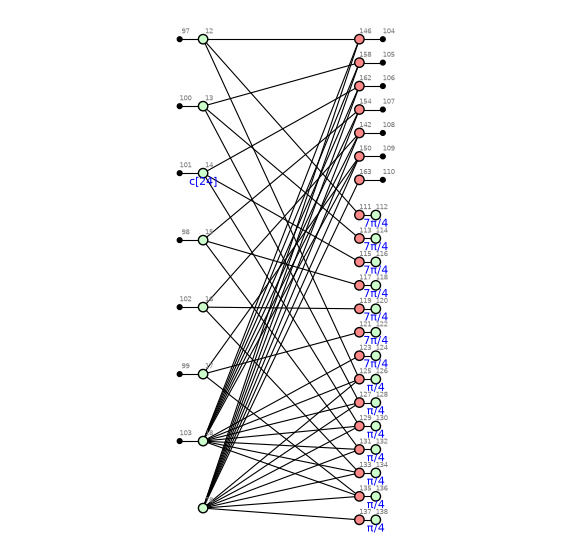

In [6]:
def names_of(h):
    name = {}
    for b in h.inputs():
        (w,) = h.neighbors(b)
        name[w] = 'in {}'.format(get_logical_qubit(h, b))
    for b in h.outputs():
        (w,) = h.neighbors(b)
        name[w] = 'out {}'.format(get_logical_qubit(h, b))
    k = 0
    for v in sorted(h.vertices()):
        if v not in name and h.type(v) == VertexType.Z and not is_leaf(h, v):
            k += 1
            name[v] = 'z{}'.format(k)
    return name


name = names_of(h)
print("vertex numbers:", {n: v for v, n in sorted(name.items(), key=lambda kv: kv[0])})
zx.draw_matplotlib(phases_modulo(h, res.constraints), labels=True, figsize=(7, 7))

In [7]:
out_of = {name[v]: sorted(name[w] for w in h.neighbors(v) if h.type(w) == VertexType.Z)
          for b in h.outputs() for v in h.neighbors(b)}

print("Z-spiders (phase; phase given the detectors; outputs it is joined to):")
for v in sorted((v for v in h.vertices() if h.type(v) == VertexType.Z and not is_leaf(h, v)), key=lambda v: name[v]):
    joined = sorted((o for o, zs in out_of.items() if name[v] in zs), key=lambda o: int(o.split()[1]))
    print("  {:6s} {:22s} {:10s} {}".format(name[v], str(h.phase(v)), str(reduce_modulo(h.phase(v), res.constraints)),
                                           ', '.join(joined) or '-'))

print()
print("Output X-spiders (the Z-spiders each output reads):")
for o, zs in sorted(out_of.items(), key=lambda kv: int(kv[0].split()[1])):
    print("  {:7s} {}".format(o, ' + '.join(zs)))

print()
print("Gadgets (angle; the parity it reads):")
for leaf in leaves:
    (hub,) = list(h.neighbors(leaf))
    read = sorted(name[w] for w in h.neighbors(hub) if w != leaf)
    what = [o for o, zs in out_of.items() if zs == read]
    if len(read) == 1 and read[0].startswith('in'):
        what.append('input ' + read[0].split()[1])
    print("  {:5s} {:24s} {}".format(str(h.phase(leaf)), ' + '.join(read),
                                     "(= the value of " + ', '.join(what) + ")" if what else ""))

Z-spiders (phase; phase given the detectors; outputs it is joined to):
  in 0   0                      0          out 0
  in 11  0                      0          out 11
  in 14  c[24] + c[27] + c[28]  0          out 0, out 3, out 6, out 8, out 9, out 11
  in 3   c[28]                  0          out 3
  in 6   c[27]                  c[24]      out 6
  in 8   0                      0          out 8
  in 9   0                      0          out 9
  z1     c[24] + c[27] + c[28]  0          out 0, out 3, out 6, out 8, out 9, out 11, out 14

Output X-spiders (the Z-spiders each output reads):
  out 0   in 0 + in 14 + z1
  out 3   in 14 + in 3 + z1
  out 6   in 14 + in 6 + z1
  out 8   in 14 + in 8 + z1
  out 9   in 14 + in 9 + z1
  out 11  in 11 + in 14 + z1
  out 14  z1

Gadgets (angle; the parity it reads):
  7/4   in 0                     (= the value of input 0)
  7/4   in 3                     (= the value of input 3)
  7/4   in 6                     (= the value of input 6)
  7/4   

**Reading it.**

* The seven 7π/4 gadgets each read one input: they are **T† on the seven code qubits**, at the start of the block.
* The seven π/4 gadgets each read exactly what one output reads: they are **T on the seven code qubits**, at the end.
* What is left in between is Clifford. With the summation variable m = `z1` + `in 14`, every output q reads `in q` + m (for q = 14 too), so the sum over m gives I + X⊗7. Given the detectors, the only phase left is π·`c[24]` on `in 6`, i.e. Z on qubit 6 before it. Z on qubit 6 anticommutes with X⊗7, so the middle is Z₆^c[24] (I + (−1)^c[24] X⊗7): the projector onto the (−1)^c[24] eigenspace of X⊗7, then Z on qubit 6 when `c[24]` = 1.
* With the T gates around it, and since T Z T† = Z, the whole double-check is, up to a scalar,

  Z₆^c[24] · (I + (−1)^c[24] H⊗7),  with  H = T X T† = (X + Y)/√2,

  on the seven code qubits: it measures H⊗7 with outcome `c[24]`, and applies Z to qubit 6 when `c[24]` = 1.

The next cell checks this last statement against the double-check's diagram, by tensor contraction, in every run the block's detectors allow.

In [8]:
import numpy as np
from functools import reduce

I2, X, Y, Z = np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1, -1])
H = (X + Y) / np.sqrt(2)
qubits = [get_logical_qubit(g, b) for b in g.inputs()]
assert qubits == [get_logical_qubit(g, b) for b in g.outputs()] == [0, 3, 6, 8, 9, 11, 14]


def expected(c24):
    # Z_6^c24 (I + (-1)^c24 H^7) on the code qubits (first qubit = most significant bit)
    correction = reduce(np.kron, [Z if (q == 6 and c24) else I2 for q in qubits])
    return correction @ (np.eye(2 ** 7) + (-1) ** c24 * reduce(np.kron, [H] * 7))


for a in runs:
    dc = zx.tensor_to_matrix(zx.tensorfy(g.substitute_variables(a), preserve_scalar=False), 7, 7)
    print("c[24] = {}:  double-check = scalar * expected: {}".format(
        a['c[24]'], zx.compare_tensors(dc, expected(a['c[24]']), preserve_scalar=False)))

c[24] = 0:  double-check = scalar * expected: True


c[24] = 1:  double-check = scalar * expected: True


In [9]:
poly, _ = phase_polynomial(h)
term = lambda m: '*'.join(sorted(name[v[1]] if isinstance(v, tuple) else str(v) for v in m))
print("phase polynomial of the gadgets, in units of pi (monomials in the bits of the Z-spiders):")
for m, c in sorted(poly.items(), key=lambda kv: (len(kv[0]), term(kv[0]))):
    print("  {:28s} {}".format(term(m), c))

phase polynomial of the gadgets, in units of pi (monomials in the bits of the Z-spiders):
  in 14                        5/4
  z1                           7/4
  in 0*in 14                   3/2
  in 0*z1                      3/2
  in 11*in 14                  3/2
  in 11*z1                     3/2
  in 14*in 3                   3/2
  in 14*in 6                   3/2
  in 14*in 8                   3/2
  in 14*in 9                   3/2
  in 14*z1                     1
  in 3*z1                      3/2
  in 6*z1                      3/2
  in 8*z1                      3/2
  in 9*z1                      3/2
  in 0*in 14*z1                1
  in 11*in 14*z1               1
  in 14*in 3*z1                1
  in 14*in 6*z1                1
  in 14*in 8*z1                1
  in 14*in 9*z1                1


## Two more checks

With the gadget step switched off (`gadgets=False`) the result is the same diagram: here the 14 gadgets read 14 different parities, and the step changes nothing. In the whole program they read the code's variables, and there the 15 gadgets of the circuit become a single T† gadget on the logical qubit (`Cultivation.ipynb`, Part 4).

The last cell prints what the level-up summary says about this block, inside the program: a logical measurement in the basis {T†|+⟩, T†|−⟩} with outcome `c[24]`.

In [10]:
res_fixed = reduce_gpf(g, gadgets=False)
h2 = res_fixed.graph
print("gadgets=False:", spiders(h2), "spiders,", sum(1 for v in h2.vertices() if is_leaf(h2, v)), "gadget leaves;",
      "same detectors:", [str(d) for d in res_fixed.detectors] == [str(d) for d in res.detectors], ";",
      "same map in all allowed runs:",
      equal_for_all_assignments(res.to_graph(), res_fixed.to_graph(), names, res.constraints))

gadgets=False: 43 spiders, 14 gadget leaves; same detectors: True ; same map in all allowed runs: True


In [11]:
print(p.summary(level).blocks[DC].describe())

Block 3 'double-check' (cultivation) -- stages 3, 4
  code before: [[7,1,3]] on qubits 0,3,6,8,9,11,14 (non-Clifford logical content)
  code after:  [[7,1,3]] on qubits 0,3,6,8,9,11,14 (non-Clifford logical content)
  logical action: a logical measurement in the basis {T^dag|+>, T^dag|->}: T^dag|+> when c[24] = 0; T^dag|-> when c[24] = 1
  measurements: 7 (4 fixed, 2 frame, 1 tied)
  ok      stays in the same code
  ok      measures the logical qubit in the basis {T^dag|+>, T^dag|->}
  ok      its outcome (c[24]) is predicted by earlier outcomes, so the check can reject a wrong state
